In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage import data

print("Libraries imported successfully!")

Libraries imported successfully!


Image shape: (512, 512)
Image loaded successfully!


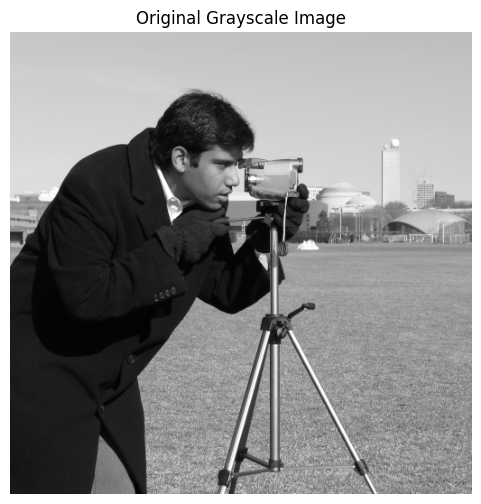

In [ ]:
# Load a sample grayscale image
img = data.camera()

# Convert to float for processing
img = img.astype(np.float32)

print("Image shape:", img.shape)
print("Image loaded successfully!")

plt.figure(figsize=(6, 6))
plt.imshow(img, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis('off')
plt.show()

In [ ]:
# Compute 2D Fourier Transform
dft = np.fft.fft2(img)

print("DFT computed successfully!")

DFT computed successfully!


In [ ]:
# Shift the zero-frequency component to the center
dft_shift = np.fft.fftshift(dft)

print("Zero-frequency component shifted to center.")

Zero-frequency component shifted to center.


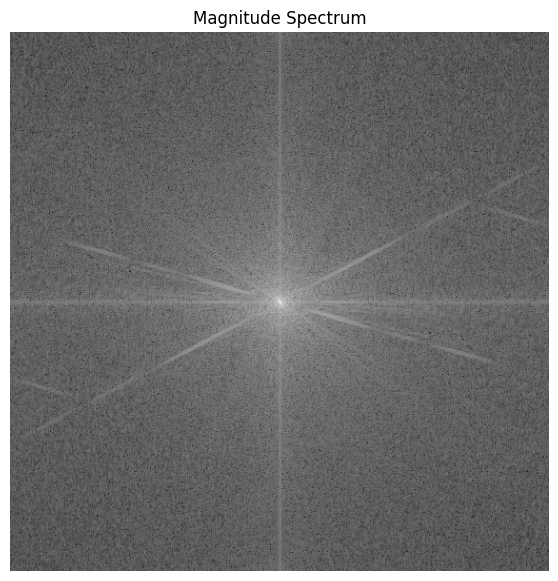

In [ ]:
# Calculate magnitude spectrum
magnitude_spectrum = np.abs(dft_shift)

# Log transformation for better visualization
magnitude_spectrum_log = np.log(1 + magnitude_spectrum)

plt.figure(figsize=(7, 7))
plt.imshow(magnitude_spectrum_log, cmap='gray')
plt.title("Magnitude Spectrum")
plt.axis('off')
plt.show()

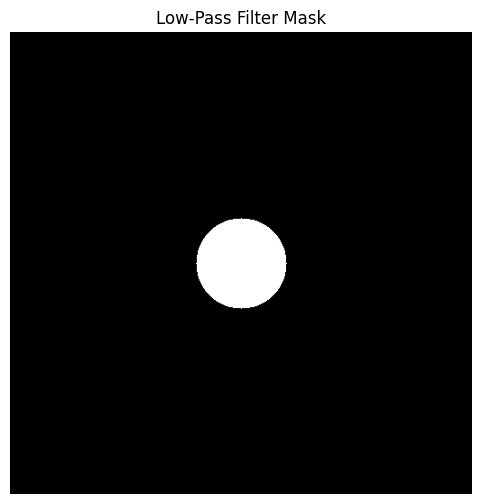

In [ ]:
rows, cols = img.shape

# Center of frequency spectrum
crow, ccol = rows // 2, cols // 2

# Radius of low-pass filter
radius = 50

# Create empty mask
low_pass_mask = np.zeros((rows, cols), np.float32)

# Create circular low-pass filter
cv2.circle(
    low_pass_mask,
    (ccol, crow),
    radius,
    1,
    -1
)

# Apply filter
low_pass_dft = dft_shift * low_pass_mask

# Display filter
plt.figure(figsize=(6, 6))
plt.imshow(low_pass_mask, cmap='gray')
plt.title("Low-Pass Filter Mask")
plt.axis('off')
plt.show()

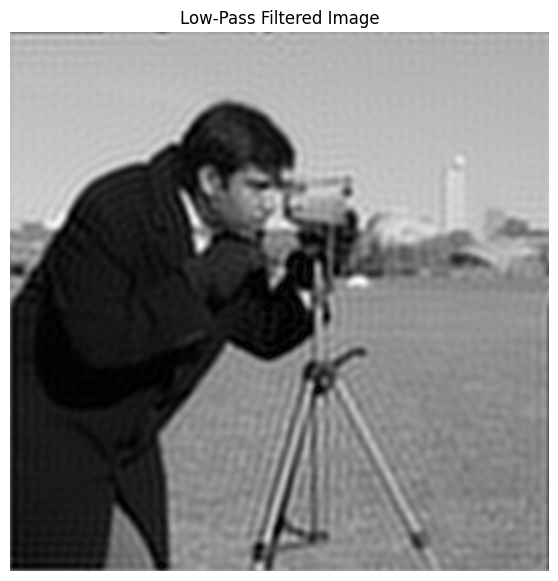

In [ ]:
# Shift frequency spectrum back
low_pass_ishift = np.fft.ifftshift(low_pass_dft)

# Inverse Fourier Transform
low_pass_image = np.fft.ifft2(low_pass_ishift)

# Take real part
low_pass_image = np.abs(low_pass_image)

# Display result
plt.figure(figsize=(7, 7))
plt.imshow(low_pass_image, cmap='gray')
plt.title("Low-Pass Filtered Image")
plt.axis('off')
plt.show()

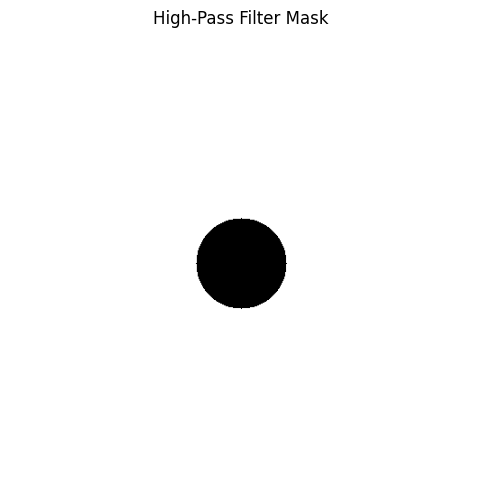

In [ ]:
# Create high-pass filter
high_pass_mask = 1 - low_pass_mask

# Apply high-pass filter
high_pass_dft = dft_shift * high_pass_mask

# Display mask
plt.figure(figsize=(6, 6))
plt.imshow(high_pass_mask, cmap='gray')
plt.title("High-Pass Filter Mask")
plt.axis('off')
plt.show()

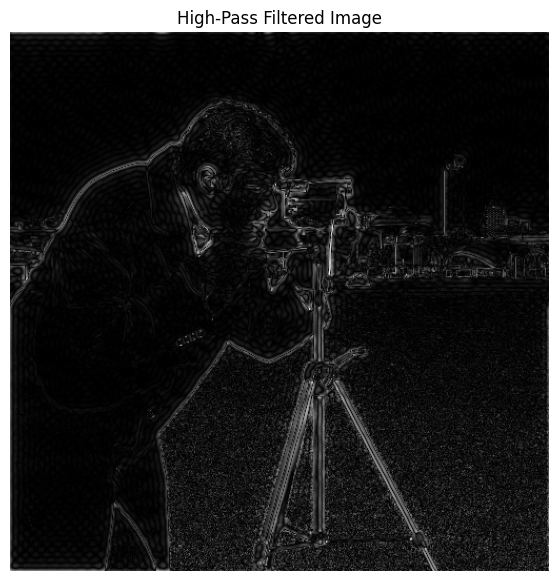

In [ ]:
# Shift back
high_pass_ishift = np.fft.ifftshift(high_pass_dft)

# Inverse Fourier Transform
high_pass_image = np.fft.ifft2(high_pass_ishift)

# Take absolute value
high_pass_image = np.abs(high_pass_image)

# Display
plt.figure(figsize=(7, 7))
plt.imshow(high_pass_image, cmap='gray')
plt.title("High-Pass Filtered Image")
plt.axis('off')
plt.show()

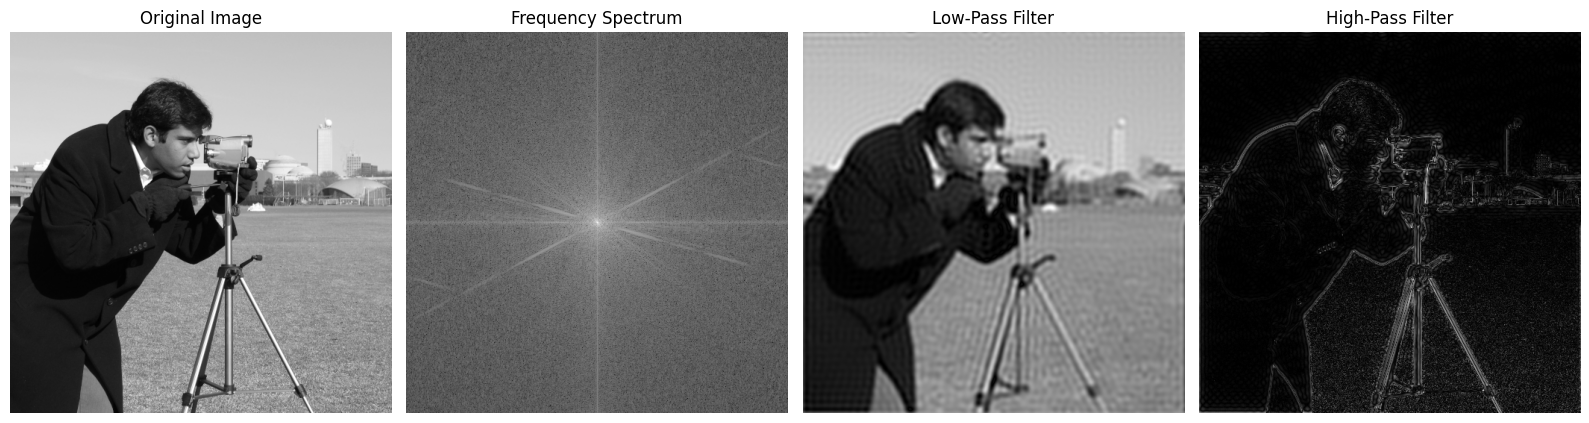

In [ ]:
plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(magnitude_spectrum_log, cmap='gray')
plt.title("Frequency Spectrum")
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(low_pass_image, cmap='gray')
plt.title("Low-Pass Filter")
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(high_pass_image, cmap='gray')
plt.title("High-Pass Filter")
plt.axis('off')

plt.tight_layout()
plt.show()

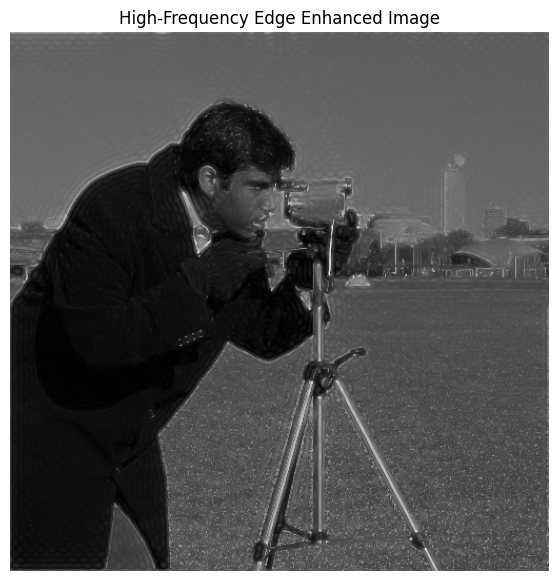

In [ ]:
# Enhance edges using high-frequency information
edge_enhanced = img + 2 * high_pass_image

# Normalize to 0-255
edge_enhanced = cv2.normalize(
    edge_enhanced,
    None,
    0,
    255,
    cv2.NORM_MINMAX
)

plt.figure(figsize=(7, 7))
plt.imshow(edge_enhanced, cmap='gray')
plt.title("High-Frequency Edge Enhanced Image")
plt.axis('off')
plt.show()

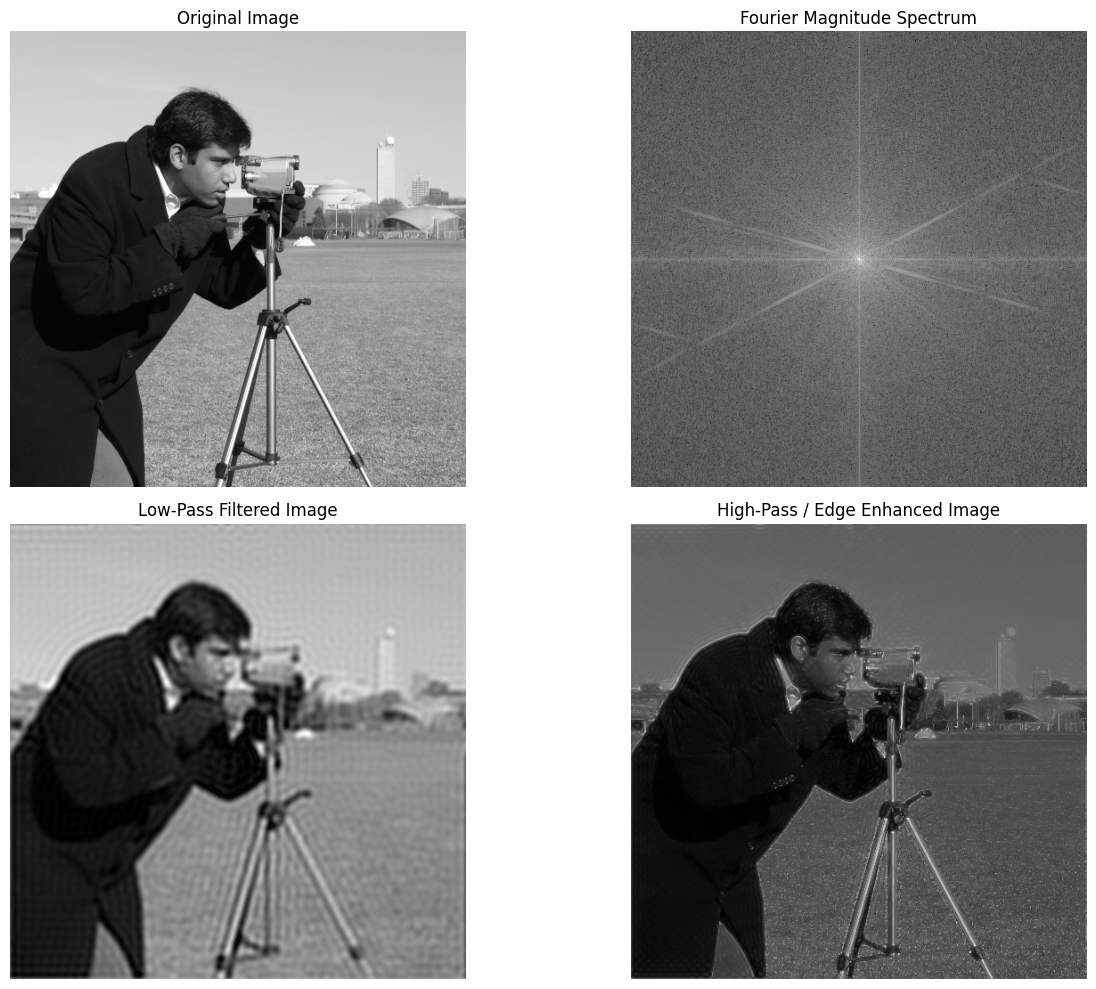

In [ ]:
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(magnitude_spectrum_log, cmap='gray')
plt.title("Fourier Magnitude Spectrum")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(low_pass_image, cmap='gray')
plt.title("Low-Pass Filtered Image")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(edge_enhanced, cmap='gray')
plt.title("High-Pass / Edge Enhanced Image")
plt.axis('off')

plt.tight_layout()
plt.show()

Ques 1- What is the Fourier Transform? Why is it important in digital image processing?


Ans -The Fourier Transform is a mathematical technique used to convert an image from the spatial domain into the frequency domain. Instead of representing an image using individual pixel intensities, it represents the image using different frequency components. Low-frequency components represent smooth areas and gradual intensity changes, while high-frequency components represent edges, fine details, and noise. It is important in digital image processing because it allows us to analyze and selectively modify these frequency components for applications such as image filtering, noise removal, sharpening, enhancement, and image restoration.

Q2. Differentiate between the spatial domain and the frequency domain.


Ans - The spatial domain represents an image directly using its pixel intensity values, whereas the frequency domain represents the image using its frequency components. In the spatial domain, operations are performed directly on pixels, while in the frequency domain, the image is first converted using the Fourier Transform and then filters are applied to selected frequency components. Spatial-domain processing is commonly used for local operations such as smoothing and edge detection, while frequency-domain processing is useful when we need precise control over low- and high-frequency information.

Ques 3 - What is the significance of the Discrete Fourier Transform (DFT) in image processing?


Ans - The Discrete Fourier Transform (DFT) converts a digital image from the spatial domain into the frequency domain. It helps identify and analyze different frequency components present in an image. By using DFT, unwanted frequencies can be removed or useful frequencies can be enhanced. It is therefore useful for noise reduction, image smoothing, sharpening, image restoration, frequency analysis, and feature extraction.

Ques 4 - Explain the purpose of shifting the zero-frequency component to the center of the frequency spectrum.


Ans - In the Fourier spectrum, the zero-frequency or lowest-frequency component is normally located at the corner of the image. Shifting it to the center makes the frequency spectrum easier to visualize and analyze. After shifting, low-frequency components appear near the center and high-frequency components appear farther away from the center. This arrangement also makes it easier to design and apply circular low-pass and high-pass filters.

Ques 5 - Compare Low-Pass Frequency Filters and High-Pass Frequency Filters with suitable applications.


Ans - A Low-Pass Filter allows low-frequency components to pass while suppressing high-frequency components. It produces a smoother image and can be used for noise reduction, image smoothing, and removal of fine details. A High-Pass Filter allows high-frequency components to pass while suppressing low-frequency components. It emphasizes edges, boundaries, and fine details and is commonly used for image sharpening, edge enhancement, and feature extraction.

Ques 6 - What is the role of the Inverse Fourier Transform (IDFT) in image reconstruction?


Ans - The Inverse Fourier Transform, or IDFT, converts an image from the frequency domain back into the spatial domain. After applying a frequency-domain filter, the modified frequency components cannot directly be viewed as a normal image. IDFT reconstructs these filtered components into an image that can be displayed and analyzed. Therefore, IDFT is an essential step for obtaining the final filtered image after frequency-domain processing.

Ques 7 - Why is frequency-domain filtering preferred for certain image enhancement tasks?


Ans - Frequency-domain filtering is preferred for certain image enhancement tasks because it provides direct control over different frequency components of an image. Low-frequency components can be preserved or removed to control smooth regions, while high-frequency components can be preserved or enhanced to emphasize edges and details. This makes frequency-domain filtering particularly useful for noise removal, sharpening, image restoration, and analysis of repetitive or periodic patterns.

Ques 8 - Mention four real-world applications where Fourier Transform is used in computer vision and image analysis.


Ans - Fourier Transform is used in many real-world computer vision and image analysis applications. Four important applications are medical image enhancement, where MRI and CT images can be processed; satellite and remote-sensing image analysis, where image quality and patterns can be analyzed; biometric systems, where useful features such as fingerprint details can be enhanced; and image restoration, where unwanted noise and distortions can be reduced. It is also used in image compression, texture analysis, and scientific imaging.

Ques 9 - Compare frequency-domain filtering with spatial-domain filtering based on computational efficiency and practical applications.


Ans - Spatial-domain filtering operates directly on image pixels and is generally simple and efficient for small filters such as basic smoothing and edge-detection kernels. Frequency-domain filtering first converts the image using the Fourier Transform, applies a filter to its frequency components, and then uses the Inverse Fourier Transform to reconstruct the image. Although frequency-domain filtering has the additional computational cost of transformations, it can be more efficient for large filters and complex global operations, especially when Fast Fourier Transform (FFT) algorithms are used. Therefore, spatial filtering is often preferred for simple local operations, while frequency filtering is useful for large-scale and frequency-specific image processing tasks.

Ques 10 - How does frequency-domain filtering improve the performance of image restoration and feature extraction techniques?


Ans - Frequency-domain filtering improves image restoration by allowing unwanted frequency components, such as certain types of noise, to be selectively suppressed while preserving useful image information. It can also enhance high-frequency components containing edges and fine details, which are important for feature extraction. As a result, important structures such as boundaries, textures, and edges become more distinguishable, helping computer vision systems perform tasks such as object detection, image matching, and pattern recognition more effectively.